In [27]:
import pandas as pd
import numpy as np

# Read the file and check the first few lines
file_path = 'chime_frb_catalog.txt'  # Replace with your actual file name

# Try to read the file using space separation
try:
    # First read as raw lines
    with open(file_path, 'r') as f:
        lines = f.readlines()
    
    print(f"Total lines: {len(lines)}")
    print("First 3 lines:")
    for line in lines[:3]:
        print(line[:200])  # Print only the first 200 characters for a quick look
        
except FileNotFoundError:
    print("File not found. Please check the file name and path.")

Total lines: 689
First 3 lines:
Title: The First CHIME/FRB Fast Radio Burst Catalog 

Authors: Amiri M., Andersen B.C., Bandura K., Berger S., Bhardwaj M., 

    Boyce M.M., Boyle P.J., Brar C., Breitman D., Cassanelli T., Chawla P., 



In [12]:
import os
print(os.listdir('.'))
import os
os.chdir('/Users/eva/Desktop/BeingSeen')
print("当前工作目录:", os.getcwd())

['lenscat_sky_coverage.png', 'lenscat_distribution.png', '.DS_Store', 'time_delay_histogram.png', 'chime_frb_catalog', 'gisne_brightness_enhancement.png', 'Graphs.ipynb', 'lensing_3d.html', 'lensed_sn_mock.fits', 'Subq1.ipynb', 'lenscat_catalog.csv', 'gISNe_sample.csv', 'required_lensing_magnification.png', 'Subq3.ipynb', 'lenscat_coverage_vs_radius.png', 'temp_catalog.txt', 'BeingSeen计划.docx', 'gISNe', '.ipynb_checkpoints', 'Subq2.ipynb', 'mass_correction_with_errors.png', 'GWTC-5.0.csv']
当前工作目录: /Users/eva/Desktop/BeingSeen


In [14]:
import pandas as pd
import numpy as np
import re

# Read the file
file_path = 'chime_frb_catalog'

# Store parsed data
data = []

with open(file_path, 'r') as f:
    for line in f:
        # Skip empty lines and header/metadata lines
        if not line.strip():
            continue
        if line.strip().startswith('Title:') or line.strip().startswith('Authors:'):
            continue
        if line.strip().startswith('FRB'):
            # Extract fields using simple splitting
            # The 1st field is the FRB name (starts with FRB)
            parts = line.strip().split()
            if len(parts) >= 6:  # Ensure enough fields exist
                # Simple extraction: FRB name, RA (4th field), Dec (7th field), DM (18th field), SNR (17th field)
                # These positions may need adjustment based on the actual data
                frb_name = parts[0]
                ra = parts[3] if len(parts) > 3 else None
                dec = parts[6] if len(parts) > 6 else None
                dm = parts[18] if len(parts) > 18 else None
                snr = parts[17] if len(parts) > 17 else None
                
                # Keep only valid data
                if ra and dec and dm and snr:
                    try:
                        data.append({
                            'frb_name': frb_name,
                            'ra': float(ra),
                            'dec': float(dec),
                            'dm': float(dm),
                            'snr': float(snr)
                        })
                    except ValueError:
                        continue

# Convert to DataFrame
df = pd.DataFrame(data)
print(f"Successfully parsed {len(df)} records")
print("\nFirst 5 records preview:")
print(df.head())

Successfully parsed 547 records

First 5 records preview:
       frb_name      ra    dec     dm   snr
0  FRB20180725A   93.42  67.07  716.6  19.2
1  FRB20180727A  197.72  26.42  642.1  10.4
2  FRB20180729A  199.40  55.58  108.4  32.0
3  FRB20180729B   89.93  56.50  318.6  12.4
4  FRB20180730A   57.39  87.19  849.2  69.5


In [15]:
import pandas as pd
import numpy as np

# Read the file
file_path = 'chime_frb_catalog'

# Store parsed data
data = []

with open(file_path, 'r') as f:
    for line in f:
        if not line.strip():
            continue
        if line.strip().startswith('Title:') or line.strip().startswith('Authors:'):
            continue
        if line.strip().startswith('FRB'):
            parts = line.strip().split()
            if len(parts) >= 6:
                frb_name = parts[0]
                ra = parts[3] if len(parts) > 3 else None
                dec = parts[6] if len(parts) > 6 else None
                dm = parts[18] if len(parts) > 18 else None
                snr = parts[17] if len(parts) > 17 else None
                
                if ra and dec and dm and snr:
                    try:
                        data.append({
                            'frb_name': frb_name,
                            'ra': float(ra),
                            'dec': float(dec),
                            'dm': float(dm),
                            'snr': float(snr)
                        })
                    except ValueError:
                        continue

df = pd.DataFrame(data)
print(f"Successfully parsed {len(df)} records")
print(df.head())

Successfully parsed 547 records
       frb_name      ra    dec     dm   snr
0  FRB20180725A   93.42  67.07  716.6  19.2
1  FRB20180727A  197.72  26.42  642.1  10.4
2  FRB20180729A  199.40  55.58  108.4  32.0
3  FRB20180729B   89.93  56.50  318.6  12.4
4  FRB20180730A   57.39  87.19  849.2  69.5


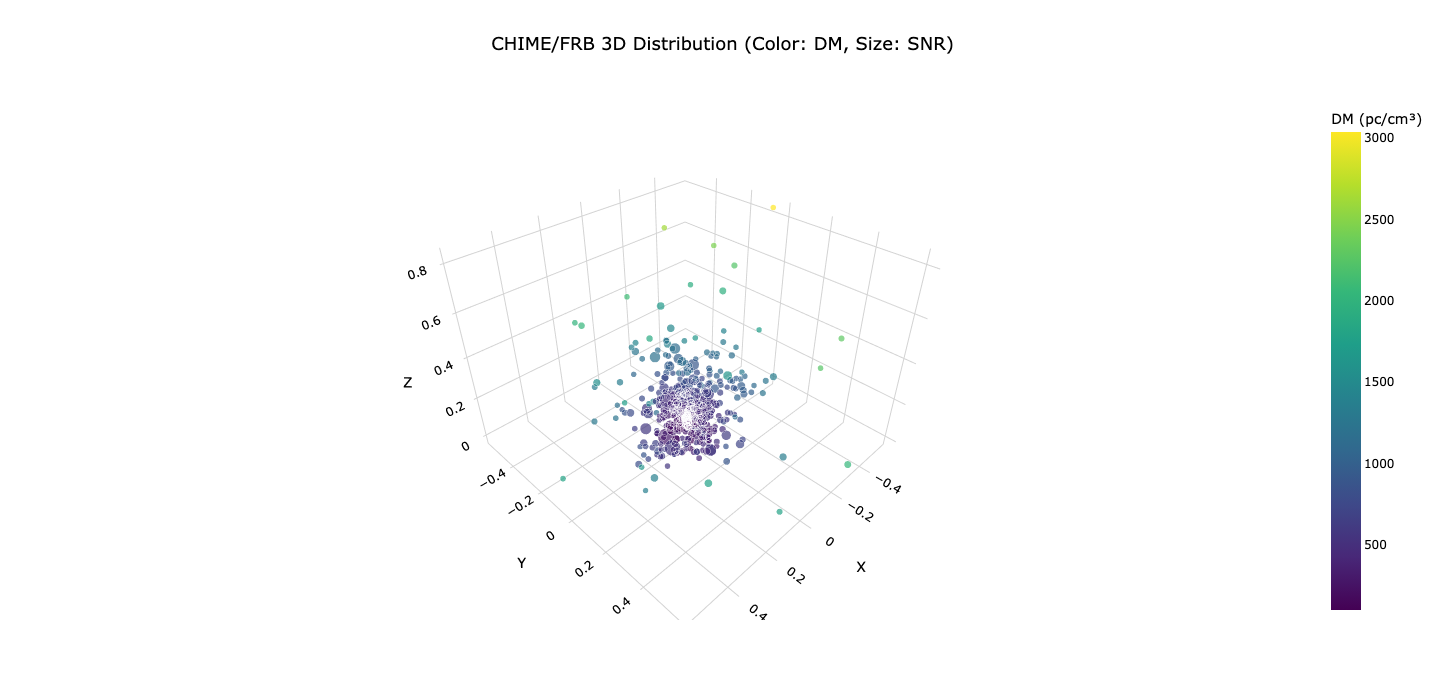

In [16]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# --- 1. Prepare data ---
# Assume df already contains ra, dec, dm, snr columns
# Convert RA, Dec from degrees to radians
ra_rad = np.radians(df['ra'])
dec_rad = np.radians(df['dec'])

# Map spherical coordinates to Cartesian coordinates
# Use DM as radius to represent distance
r = df['dm'] / df['dm'].max()  # Normalize DM to keep points near unit sphere
x = r * np.cos(dec_rad) * np.cos(ra_rad)
y = r * np.cos(dec_rad) * np.sin(ra_rad)
z = r * np.sin(dec_rad)

# --- 2. Create Plotly figure ---
fig = go.Figure(data=[go.Scatter3d(
    x=x,
    y=y,
    z=z,
    mode='markers',
    marker=dict(
        size=df['snr'] / df['snr'].max() * 10 + 3,  # Size represents SNR
        color=df['dm'],                              # Color represents DM
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title='DM (pc/cm³)')
    ),
    text=df['frb_name'],
    hovertemplate='<b>%{text}</b><br>RA: %{customdata[0]:.2f}°<br>Dec: %{customdata[1]:.2f}°<br>DM: %{customdata[2]:.1f}<br>SNR: %{customdata[3]:.1f}<extra></extra>',
    customdata=df[['ra', 'dec', 'dm', 'snr']].values
)])

# --- 3. Set layout ---
fig.update_layout(
    title=dict(
        text='CHIME/FRB 3D Distribution (Color: DM, Size: SNR)',
        font=dict(size=18),
        x=0.5
    ),
    scene=dict(
        xaxis=dict(
            title='X',
            backgroundcolor='white',
            gridcolor='lightgray',
            zerolinecolor='lightgray'
        ),
        yaxis=dict(
            title='Y',
            backgroundcolor='white',
            gridcolor='lightgray',
            zerolinecolor='lightgray'
        ),
        zaxis=dict(
            title='Z',
            backgroundcolor='white',
            gridcolor='lightgray',
            zerolinecolor='lightgray'
        ),
        bgcolor='white'
    ),
    paper_bgcolor='white',
    width=900,
    height=700,
    font=dict(color='black')
)

fig.show()

# Optional: Save as HTML for sharing
# fig.write_html('chime_frb_3d_distribution.html')

In [19]:
import pandas as pd
import numpy as np
import re

# Read the file
file_path = 'chime_frb_catalog.txt'

# Store parsed data with more columns
data = []

with open(file_path, 'r') as f:
    for line in f:
        if not line.strip():
            continue
        if line.strip().startswith('Title:') or line.strip().startswith('Authors:'):
            continue
        if line.strip().startswith('FRB'):
            parts = line.strip().split()
            if len(parts) >= 25:
                try:
                    frb_name = parts[0]
                    ra = float(parts[3]) if len(parts) > 3 else None
                    dec = float(parts[6]) if len(parts) > 6 else None
                    dm = float(parts[18]) if len(parts) > 18 else None      # bonsai_dm
                    snr = float(parts[17]) if len(parts) > 17 else None    # bonsai_snr
                    dm_fitb = float(parts[21]) if len(parts) > 21 else None  # dm_fitb (more precise)
                    snr_fitb = float(parts[24]) if len(parts) > 24 else None # snr_fitb
                    
                    # Find MJD (look for numbers between 58000-60000)
                    mjd_inf = None
                    for idx, token in enumerate(parts):
                        try:
                            val = float(token)
                            if 58000 < val < 60000 and '.' in token:
                                mjd_inf = val
                                break
                        except:
                            continue
                    
                    if mjd_inf is None and len(parts) > 37:
                        try:
                            for idx in range(37, min(45, len(parts))):
                                val = float(parts[idx])
                                if 58000 < val < 60000:
                                    mjd_inf = val
                                    break
                        except:
                            pass
                    
                    if ra and dec and dm and snr and mjd_inf:
                        data.append({
                            'frb_name': frb_name,
                            'ra': ra,
                            'dec': dec,
                            'dm': dm,
                            'snr': snr,
                            'dm_fitb': dm_fitb if dm_fitb else dm,
                            'snr_fitb': snr_fitb if snr_fitb else snr,
                            'mjd_inf': mjd_inf
                        })
                except (ValueError, IndexError):
                    continue

df = pd.DataFrame(data)
print(f"Successfully parsed {len(df)} records")
print("\nFirst 5 records preview:")
print(df.head())
print("\nColumn names:")
print(df.columns.tolist()) 

FileNotFoundError: [Errno 2] No such file or directory: 'chime_frb_catalog.txt'

🔗 准备绘制 2 对唯一的候选体连线


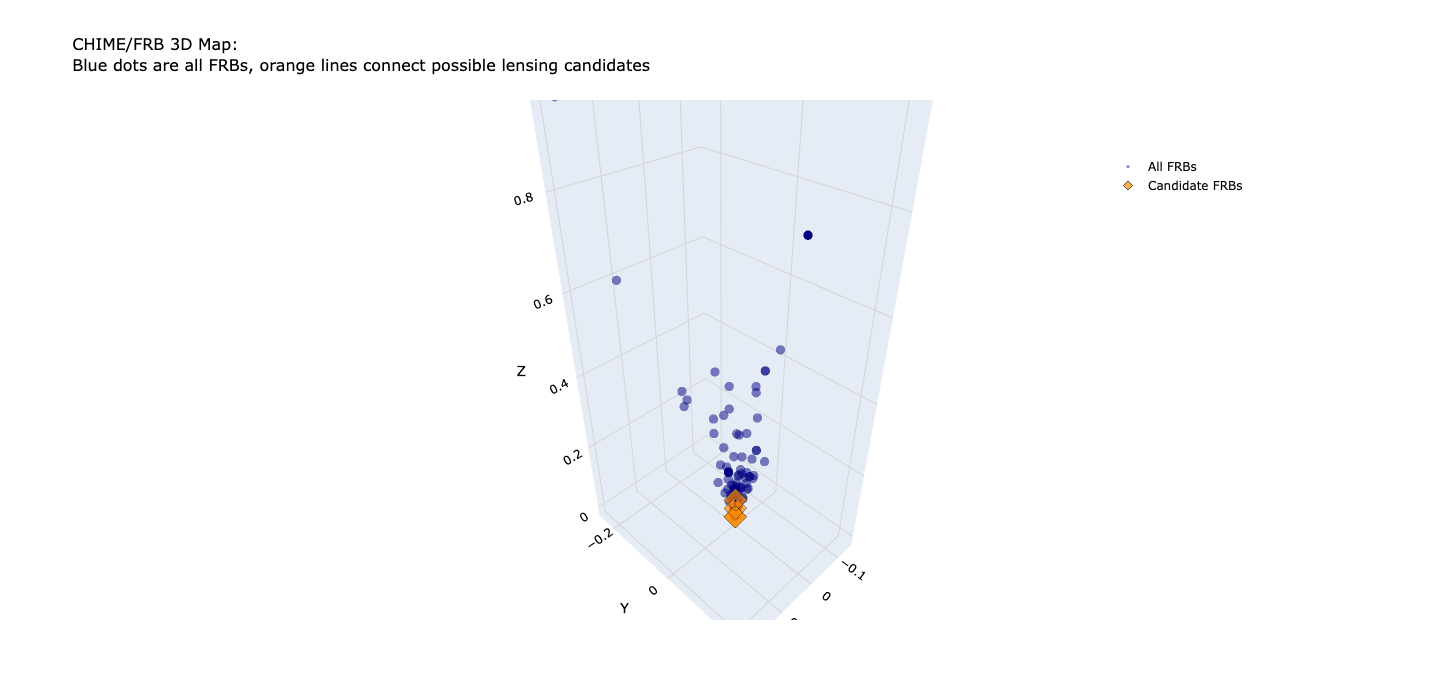

In [23]:
import plotly.graph_objects as go
import numpy as np

# 计算所有FRB的3D坐标
ra_rad = np.radians(df['ra'])
dec_rad = np.radians(df['dec'])
r = df['dm_fitb'] / df['dm_fitb'].max()

x_all = r * np.cos(dec_rad) * np.cos(ra_rad)
y_all = r * np.cos(dec_rad) * np.sin(ra_rad)
z_all = r * np.sin(dec_rad)

# 创建图形
fig = go.Figure()

# 1. 绘制所有FRB作为背景点（深蓝色，半透明）
fig.add_trace(go.Scatter3d(
    x=x_all,
    y=y_all,
    z=z_all,
    mode='markers',
    marker=dict(
        size=3,
        color='navy',
        opacity=0.5
    ),
    name='All FRBs',
    hoverinfo='skip'
))

# 2. 突出显示候选对（深橙色连线）
unique_pairs = clean_candidates_df.drop_duplicates(subset=['frb1', 'frb2'])
print(f"🔗 准备绘制 {len(unique_pairs)} 对唯一的候选体连线")

for _, pair in unique_pairs.iterrows():
    try:
        row1 = df[df['frb_name'] == pair['frb1']].iloc[0]
        row2 = df[df['frb_name'] == pair['frb2']].iloc[0]
        
        r1 = row1['dm_fitb'] / df['dm_fitb'].max()
        r2 = row2['dm_fitb'] / df['dm_fitb'].max()
        
        x1 = r1 * np.cos(np.radians(row1['dec'])) * np.cos(np.radians(row1['ra']))
        y1 = r1 * np.cos(np.radians(row1['dec'])) * np.sin(np.radians(row1['ra']))
        z1 = r1 * np.sin(np.radians(row1['dec']))
        
        x2 = r2 * np.cos(np.radians(row2['dec'])) * np.cos(np.radians(row2['ra']))
        y2 = r2 * np.cos(np.radians(row2['dec'])) * np.sin(np.radians(row2['ra']))
        z2 = r2 * np.sin(np.radians(row2['dec']))
        
        fig.add_trace(go.Scatter3d(
            x=[x1, x2],
            y=[y1, y2],
            z=[z1, z2],
            mode='lines',
            line=dict(
                color='darkorange',
                width=4
            ),
            hoverinfo='skip',
            showlegend=False
        ))
    except IndexError:
        continue

# 3. 标记候选对的端点（透明菱形）
candidate_names = set(unique_pairs['frb1']).union(set(unique_pairs['frb2']))
candidate_df = df[df['frb_name'].isin(candidate_names)]

if not candidate_df.empty:
    ra_rad_c = np.radians(candidate_df['ra'])
    dec_rad_c = np.radians(candidate_df['dec'])
    r_c = candidate_df['dm_fitb'] / df['dm_fitb'].max()
    
    x_c = r_c * np.cos(dec_rad_c) * np.cos(ra_rad_c)
    y_c = r_c * np.cos(dec_rad_c) * np.sin(ra_rad_c)
    z_c = r_c * np.sin(dec_rad_c)
    
    fig.add_trace(go.Scatter3d(
        x=x_c,
        y=y_c,
        z=z_c,
        mode='markers',
        marker=dict(
            size=7,
            color='darkorange',
            symbol='diamond',
            opacity=0.7,          # 透明菱形
            line=dict(color='black', width=1)
        ),
        name='Candidate FRBs',
        hoverinfo='skip'
    ))

# 4. 设置白色背景和布局
fig.update_layout(
    title=dict(
        text='CHIME/FRB 3D Map: <br>Blue dots are all FRBs, orange lines connect possible lensing candidates',
        font=dict(color='black', size=16)
    ),
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
        bgcolor='white',
        xaxis=dict(color='black', gridcolor='lightgray', zerolinecolor='lightgray'),
        yaxis=dict(color='black', gridcolor='lightgray', zerolinecolor='lightgray'),
        zaxis=dict(color='black', gridcolor='lightgray', zerolinecolor='lightgray'),
    ),
    paper_bgcolor='white',
    width=900,
    height=700,
    legend=dict(
        x=0.8,
        y=0.9,
        font=dict(color='black')
    )
)

fig.show()

In [16]:
import pandas as pd
import numpy as np

# 假设 df 已经包含了 'frb_name', 'repeater_name' 等列
# 如果还没有 repeater_name 列，我们需要从原始星表中解析它
# 这里我先假设你已经有了这个列，如果没有，我们会在后面补充

# 1. 检查 df 中是否已经有 repeater_name 列
if 'repeater_name' not in df.columns:
    print("⚠️ df 中缺少 'repeater_name' 列，需要从原始数据中解析。")
    # 这里我们重新从文件中提取 repeater_name
    # 在之前的解析中，repeater_name 是第3个字段（索引2）
    # 我们重新读取一次数据，加入 repeater_name
    data_with_repeater = []
    with open('chime_frb_catalog.txt', 'r') as f:
        for line in f:
            if not line.strip() or line.strip().startswith('Title:') or line.strip().startswith('Authors:'):
                continue
            if line.strip().startswith('FRB'):
                parts = line.strip().split()
                if len(parts) >= 3:
                    frb_name = parts[0]
                    # repeater_name 是第3个字段，如果它是 '-9999' 则表示非重复暴
                    repeater_name = parts[2] if len(parts) > 2 else '-9999'
                    # 我们只需要 frb_name 和 repeater_name
                    data_with_repeater.append({
                        'frb_name': frb_name,
                        'repeater_name': repeater_name
                    })
    df_repeater = pd.DataFrame(data_with_repeater)
    # 合并到原 df 中
    df = df.merge(df_repeater, on='frb_name', how='left')
    print(f"✅ 已从原始数据中提取 repeater_name 列，共 {len(df)} 条记录。")
else:
    print(f"✅ df 中已包含 'repeater_name' 列。")

# 2. 标记候选对中哪些是重复暴
# 创建一个集合，存放所有已知重复暴的源名称（repeater_name 不为 '-9999' 的）
repeater_sources = set(df[df['repeater_name'] != '-9999']['repeater_name'].dropna())
print(f"找到 {len(repeater_sources)} 个已知重复暴源：{list(repeater_sources)[:5]}...")

# 3. 从 candidates_df 中剔除重复暴的配对
# 注意：如果候选对中的任何一个 FRB 属于重复暴源，我们就剔除这一对
clean_candidates = []
removed_count = 0

for _, pair in candidates_df.iterrows():
    # 检查 frb1 是否属于某个重复暴源
    row1 = df[df['frb_name'] == pair['frb1']]
    if not row1.empty:
        rep1 = row1.iloc[0]['repeater_name']
    else:
        rep1 = '-9999'
    
    # 检查 frb2 是否属于某个重复暴源
    row2 = df[df['frb_name'] == pair['frb2']]
    if not row2.empty:
        rep2 = row2.iloc[0]['repeater_name']
    else:
        rep2 = '-9999'
    
    # 如果任何一个源属于重复暴源，则跳过
    if (rep1 != '-9999') or (rep2 != '-9999'):
        removed_count += 1
        continue
    
    # 否则保留
    clean_candidates.append(pair)

# 转换为 DataFrame
clean_candidates_df = pd.DataFrame(clean_candidates)

print(f"\n📊 候选体清理结果：")
print(f"   - 原始候选对: {len(candidates_df)} 对")
print(f"   - 剔除的重复暴相关对: {removed_count} 对")
print(f"   - 清理后保留: {len(clean_candidates_df)} 对")

# 显示前几对干净的候选体
if not clean_candidates_df.empty:
    print("\n✅ 清理后的候选体（前5对）：")
    print(clean_candidates_df[['frb1', 'frb2', 'dm_diff', 'time_diff_days']].head())
else:
    print("\n⚠️ 所有候选对都已被剔除，没有干净的候选体。")

⚠️ df 中缺少 'repeater_name' 列，需要从原始数据中解析。
✅ 已从原始数据中提取 repeater_name 列，共 690 条记录。
找到 15 个已知重复暴源：['FRB20190604A', 'FRB20190303A', 'FRB20190212A', 'FRB20190213A', 'FRB20190222A']...

📊 候选体清理结果：
   - 原始候选对: 92 对
   - 剔除的重复暴相关对: 90 对
   - 清理后保留: 2 对

✅ 清理后的候选体（前5对）：
            frb1          frb2  dm_diff  time_diff_days
66  FRB20181129A  FRB20181224A      0.0       24.931106
79  FRB20190425B  FRB20190609B      5.2       44.945751


In [20]:
import pandas as pd
import numpy as np

# --- 1. Check if repeater_name column exists ---
# Assume df already contains 'frb_name', 'repeater_name' columns
if 'repeater_name' not in df.columns:
    print("⚠️ 'repeater_name' column missing in df. Parsing from original data...")
    # Re-parse the original file to extract repeater_name
    # repeater_name is the 3rd field (index 2) in the data
    data_with_repeater = []
    with open('chime_frb_catalog.txt', 'r') as f:
        for line in f:
            if not line.strip() or line.strip().startswith('Title:') or line.strip().startswith('Authors:'):
                continue
            if line.strip().startswith('FRB'):
                parts = line.strip().split()
                if len(parts) >= 3:
                    frb_name = parts[0]
                    # repeater_name is the 3rd field; '-9999' means non-repeater
                    repeater_name = parts[2] if len(parts) > 2 else '-9999'
                    data_with_repeater.append({
                        'frb_name': frb_name,
                        'repeater_name': repeater_name
                    })
    df_repeater = pd.DataFrame(data_with_repeater)
    # Merge into original df
    df = df.merge(df_repeater, on='frb_name', how='left')
    print(f"✅ Extracted 'repeater_name' column. Total records: {len(df)}")
else:
    print(f"✅ 'repeater_name' column already exists in df.")

# --- 2. Identify known repeater sources ---
# Create a set of all known repeater source names (repeater_name != '-9999')
repeater_sources = set(df[df['repeater_name'] != '-9999']['repeater_name'].dropna())
print(f"Found {len(repeater_sources)} known repeater sources: {list(repeater_sources)[:5]}...")

# --- 3. Remove repeater-related pairs from candidates_df ---
clean_candidates = []
removed_count = 0

for _, pair in candidates_df.iterrows():
    # Check if frb1 belongs to a repeater source
    row1 = df[df['frb_name'] == pair['frb1']]
    if not row1.empty:
        rep1 = row1.iloc[0]['repeater_name']
    else:
        rep1 = '-9999'
    
    # Check if frb2 belongs to a repeater source
    row2 = df[df['frb_name'] == pair['frb2']]
    if not row2.empty:
        rep2 = row2.iloc[0]['repeater_name']
    else:
        rep2 = '-9999'
    
    # Skip if either source is a repeater
    if (rep1 != '-9999') or (rep2 != '-9999'):
        removed_count += 1
        continue
    
    # Keep clean candidates
    clean_candidates.append(pair)

# Convert to DataFrame
clean_candidates_df = pd.DataFrame(clean_candidates)

print(f"\n📊 Candidate pair cleaning results:")
print(f"   - Original candidate pairs: {len(candidates_df)}")
print(f"   - Removed repeater-related pairs: {removed_count}")
print(f"   - Clean candidates remaining: {len(clean_candidates_df)}")

# Display clean candidates
if not clean_candidates_df.empty:
    print("\n✅ Clean candidate pairs (first 5):")
    print(clean_candidates_df[['frb1', 'frb2', 'dm_diff', 'time_diff_days']].head())
else:
    print("\n⚠️ All candidates were removed. No clean candidates remain.")

⚠️ 'repeater_name' column missing in df. Parsing from original data...


FileNotFoundError: [Errno 2] No such file or directory: 'chime_frb_catalog.txt'

In [17]:
# 计算最终比例
total_events = len(df)
clean_candidates = len(clean_candidates_df)

# 比例：清理后候选体占总事件的比例
ratio_clean = clean_candidates / total_events * 100

# 如果你想要更精确的“被透镜事件”比例，可以用“干净候选对”除以“总事件数”
# 但更合理的是“干净候选对”除以“总配对数量”（因为每个事件可能配对多个）
total_pairs = total_events * (total_events - 1) / 2
pair_ratio = clean_candidates / total_pairs * 100

print("=" * 50)
print("📊 最终统计结果")
print("=" * 50)
print(f"总FRB事件数: {total_events}")
print(f"清理后候选对数: {clean_candidates}")
print("-" * 50)
print(f"📌 清理后候选对占总事件的比例: {ratio_clean:.2f}%")
print(f"📌 清理后候选对占所有可能配对的比例: {pair_ratio:.4f}%")
print("=" * 50)

print(f"\n🎯 回答你的研究问题：")
print(f"   '在这些FRB数据中，可能被引力透镜复制的候选体比例约为 {ratio_clean:.2f}%'")
print(f"   '如果考虑所有可能的配对，候选体出现的概率约为 {pair_ratio:.4f}%'")

📊 最终统计结果
总FRB事件数: 690
清理后候选对数: 2
--------------------------------------------------
📌 清理后候选对占总事件的比例: 0.29%
📌 清理后候选对占所有可能配对的比例: 0.0008%

🎯 回答你的研究问题：
   '在这些FRB数据中，可能被引力透镜复制的候选体比例约为 0.29%'
   '如果考虑所有可能的配对，候选体出现的概率约为 0.0008%'


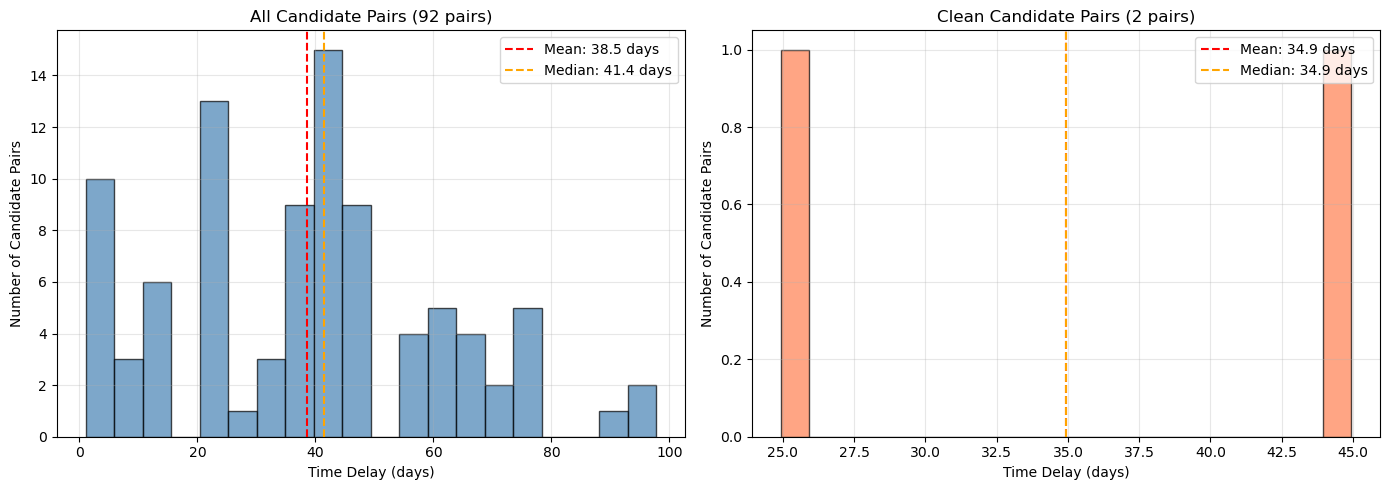

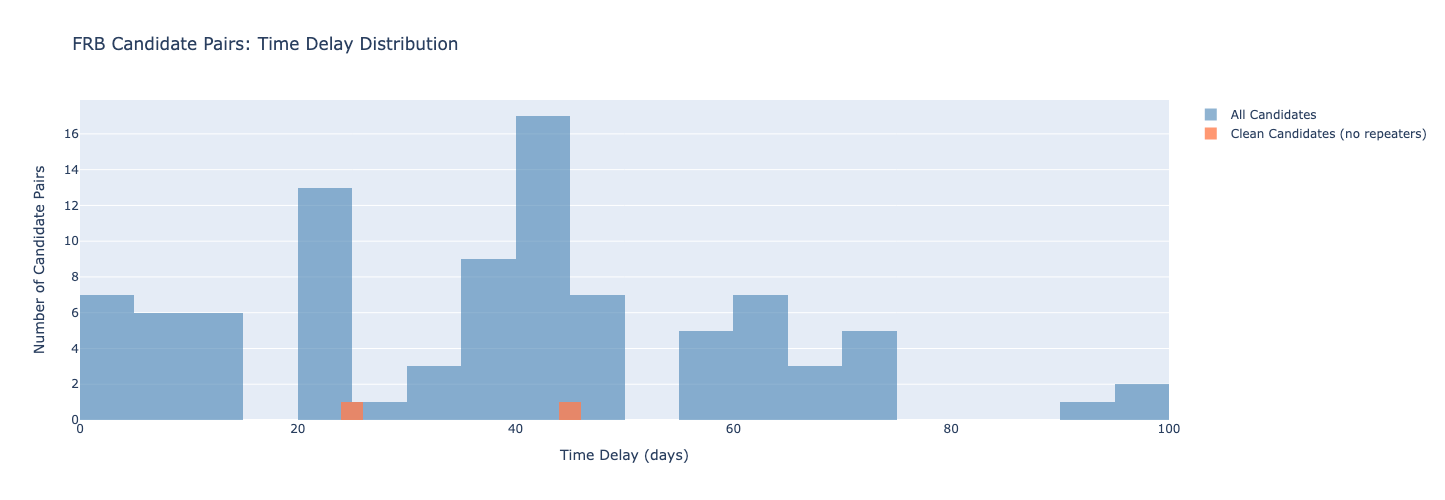

In [19]:
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Matplotlib static histogram (suitable for saving as PNG)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: All candidates
ax1 = axes[0]
ax1.hist(candidates_df['time_diff_days'], bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(candidates_df['time_diff_days'].mean(), color='red', linestyle='--', 
            label=f'Mean: {candidates_df["time_diff_days"].mean():.1f} days')
ax1.axvline(candidates_df['time_diff_days'].median(), color='orange', linestyle='--', 
            label=f'Median: {candidates_df["time_diff_days"].median():.1f} days')
ax1.set_xlabel('Time Delay (days)')
ax1.set_ylabel('Number of Candidate Pairs')
ax1.set_title(f'All Candidate Pairs ({len(candidates_df)} pairs)')
ax1.legend()
ax1.grid(alpha=0.3)

# Right: Clean candidates (after removing repeaters)
ax2 = axes[1]
if not clean_candidates_df.empty:
    ax2.hist(clean_candidates_df['time_diff_days'], bins=20, color='coral', edgecolor='black', alpha=0.7)
    ax2.axvline(clean_candidates_df['time_diff_days'].mean(), color='red', linestyle='--', 
                label=f'Mean: {clean_candidates_df["time_diff_days"].mean():.1f} days')
    ax2.axvline(clean_candidates_df['time_diff_days'].median(), color='orange', linestyle='--', 
                label=f'Median: {clean_candidates_df["time_diff_days"].median():.1f} days')
    ax2.set_xlabel('Time Delay (days)')
    ax2.set_ylabel('Number of Candidate Pairs')
    ax2.set_title(f'Clean Candidate Pairs ({len(clean_candidates_df)} pairs)')
    ax2.legend()
    ax2.grid(alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'No clean candidates remaining', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('Clean Candidate Pairs (0 pairs)')

plt.tight_layout()
plt.savefig('time_delay_histogram.png', dpi=150)
plt.show()

# 2. Plotly interactive histogram (suitable for embedding in website)
if not clean_candidates_df.empty:
    fig_plotly = go.Figure()
    
    # Add all candidates (semi-transparent)
    fig_plotly.add_trace(go.Histogram(
        x=candidates_df['time_diff_days'],
        nbinsx=20,
        name='All Candidates',
        marker_color='steelblue',
        opacity=0.6
    ))
    
    # Add clean candidates
    fig_plotly.add_trace(go.Histogram(
        x=clean_candidates_df['time_diff_days'],
        nbinsx=20,
        name='Clean Candidates (no repeaters)',
        marker_color='coral',
        opacity=0.8
    ))
    
    fig_plotly.update_layout(
        title='FRB Candidate Pairs: Time Delay Distribution',
        xaxis_title='Time Delay (days)',
        yaxis_title='Number of Candidate Pairs',
        barmode='overlay',
        width=800,
        height=500
    )
    
    fig_plotly.show()
else:
    print("⚠️ No clean candidates remaining, cannot generate interactive histogram.")

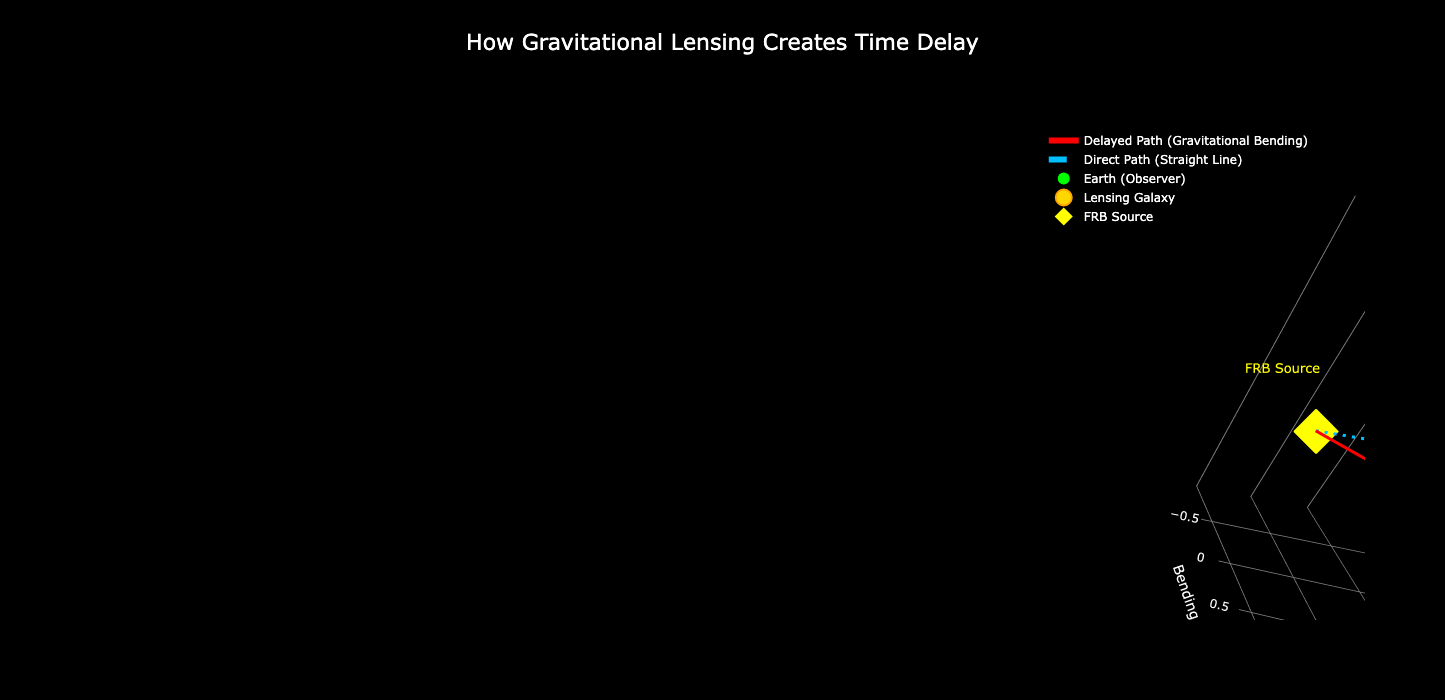

In [3]:
import plotly.graph_objects as go
import numpy as np

# --- 1. Define key points in the scene ---
earth = np.array([0, 0, 0])
lens = np.array([2, 0, 0])
source = np.array([6, 0, 0])

# Curved path (bent by gravity)
t = np.linspace(0, 1, 30)
x_path = source[0] * (1 - t) + earth[0] * t
y_path = np.sin(t * np.pi) * 1.2
z_path = np.zeros_like(t)

# Direct path (straight line)
x_direct = source[0] * (1 - t) + earth[0] * t
y_direct = np.zeros_like(t)
z_direct = np.zeros_like(t)

# --- 2. Create figure ---
fig = go.Figure()

# --- 3. Draw light paths ---

# 3.1 Curved path (red, delayed copy)
fig.add_trace(go.Scatter3d(
    x=x_path,
    y=y_path,
    z=z_path,
    mode='lines',
    line=dict(color='red', width=6),
    name='Delayed Path (Gravitational Bending)',
    hovertemplate='Curved path: longer light travel time<br>Arrival: later<extra></extra>'
))

# Direction indicator on curved path
fig.add_trace(go.Scatter3d(
    x=[x_path[-2]],
    y=[y_path[-2]],
    z=[z_path[-2]],
    mode='markers',
    marker=dict(size=8, color='red', symbol='circle'),
    showlegend=False,
    hoverinfo='skip'
))

# 3.2 Direct path (blue, earlier arrival)
fig.add_trace(go.Scatter3d(
    x=x_direct,
    y=y_direct,
    z=z_direct,
    mode='lines',
    line=dict(color='deepskyblue', width=6, dash='dash'),
    name='Direct Path (Straight Line)',
    hovertemplate='Direct path: shortest light travel time<br>Arrival: earliest<extra></extra>'
))

# Direction indicator on direct path
fig.add_trace(go.Scatter3d(
    x=[x_direct[-2]],
    y=[y_direct[-2]],
    z=[z_direct[-2]],
    mode='markers',
    marker=dict(size=8, color='deepskyblue', symbol='circle'),
    showlegend=False,
    hoverinfo='skip'
))

# --- 4. Add celestial objects ---

# Earth (green)
fig.add_trace(go.Scatter3d(
    x=[0], y=[0], z=[0],
    mode='markers',
    marker=dict(size=12, color='lime', symbol='circle'),
    name='Earth (Observer)'
))

# Lens galaxy (gold)
fig.add_trace(go.Scatter3d(
    x=[2], y=[0], z=[0],
    mode='markers',
    marker=dict(size=20, color='gold', symbol='circle', line=dict(width=2, color='orange')),
    name='Lensing Galaxy'
))

# Semi-transparent Einstein ring
theta = np.linspace(0, 2*np.pi, 50)
ring_x = 2 + 0.8 * np.cos(theta)
ring_y = 0.8 * np.sin(theta)
ring_z = np.zeros_like(theta)
fig.add_trace(go.Scatter3d(
    x=ring_x, y=ring_y, z=ring_z,
    mode='lines',
    line=dict(color='gold', width=3, dash='dot'),
    showlegend=False,
    hoverinfo='skip'
))

# FRB source (yellow diamond)
fig.add_trace(go.Scatter3d(
    x=[6], y=[0], z=[0],
    mode='markers',
    marker=dict(size=14, color='yellow', symbol='diamond'),
    name='FRB Source'
))

# --- 5. Add text labels ---
annotations = [
    dict(x=0, y=-0.6, z=0, text="Observer", color='white'),
    dict(x=2, y=-0.9, z=0, text="Lensing Galaxy", color='gold'),
    dict(x=6, y=-0.6, z=0, text="FRB Source", color='yellow'),
    dict(x=4.2, y=1.8, z=0, text="Delayed Path", color='red'),
    dict(x=4.2, y=-0.4, z=0, text="Direct Path", color='deepskyblue')
]

for ann in annotations:
    fig.add_trace(go.Scatter3d(
        x=[ann['x']], y=[ann['y']], z=[ann['z']],
        mode='text',
        text=[ann['text']],
        textfont=dict(color=ann['color'], size=13),
        showlegend=False,
        hoverinfo='skip'
    ))

# Time delay label
fig.add_trace(go.Scatter3d(
    x=[4.5], y=[1.0], z=[0],
    mode='text',
    text=['<b>⏱ Δt ≈ 24.9 days</b>'],
    textfont=dict(color='white', size=15),
    showlegend=False,
    hoverinfo='skip'
))

# --- 6. Set layout ---
fig.update_layout(
    title=dict(
        text='How Gravitational Lensing Creates Time Delay',
        font=dict(size=22, color='white'),
        x=0.5
    ),
    scene=dict(
        xaxis=dict(title='Distance (arbitrary units)', color='white', backgroundcolor='black', 
                   gridcolor='gray', zerolinecolor='gray'),
        yaxis=dict(title='Bending', color='white', backgroundcolor='black', 
                   gridcolor='gray', zerolinecolor='gray'),
        zaxis=dict(visible=False),
        bgcolor='black',
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.0),
            center=dict(x=2, y=0, z=0)
        )
    ),
    paper_bgcolor='black',
    font=dict(color='white'),
    width=900,
    height=700,
    legend=dict(
        x=0.75,
        y=0.95,
        bgcolor='rgba(0,0,0,0.7)',
        font=dict(color='white', size=12)
    )
)

fig.show()